# VR exploration behaviour: EyeNavGS (6-DoF head traces)

End-to-end analysis. Every number reported in the README is produced by this notebook and written to `results/`.
Run from the repo root after `./data/download.sh` (or execute this notebook; it calls the script if data are missing).

In [2]:
import json, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
if not (ROOT / "data/raw/EyeNavGS_Rutgers_Dataset/dataset").exists():
    subprocess.run([str(ROOT / "data/download.sh")], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import load, pipeline, analysis, plots
from src.measures import SPEED_LAG_S, MAX_ANG_DEG_S, MAX_TRANS_M_S
RES, FIG = ROOT / "results", ROOT / "figures"
RES.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plots.style()
summary = {}

## 1. Data and preprocessing decisions

**Dataset.** EyeNavGS, Rutgers subset (Ding et al., 2025; Apache-2.0), pinned commit in `data/download.sh`. 22 users x 12 3DGS scenes; per-frame head pose (+ eye gaze, unused) from a Meta Quest Pro, free standing navigation in a 3 m x 3 m area.

**Coordinate conventions** (checked on every trace below, not assumed):
- Rotating head pose and position by the scene's setting quaternion aligns the head's up axis with world +Y.
- Positions are in scene units; dividing by the scene scale gives metres (paper: scale maps virtual to real size).
- The viewing direction is local -Z (OpenXR): it agrees with walking direction (positive cosine), +Z would give the negative.

In [3]:
settings, traces = load.load_scene_settings(), load.list_traces()
checks = pd.DataFrame([{"scene": t.scene, "user": t.user,
                        **analysis.frame_checks(load.load_trace(t.path), settings.loc[t.scene, "quat"], settings.loc[t.scene, "scale"])}
                       for t in traces.itertuples()])
by_scene = checks.groupby("scene").median(numeric_only=True).join(settings["scale"])
display(by_scene.round(2))
summary["checks"] = {k: float(v) for k, v in checks.median(numeric_only=True).items()}
summary["checks"]["head_up_dot_aligned_min_scene"] = float(by_scene.head_up_dot_aligned.min())
summary["checks"]["horizontal_range_m_by_scene_min_max"] = [float(by_scene.horizontal_range_m.min()), float(by_scene.horizontal_range_m.max())]
summary["checks"]["raw_range_units_by_scene_min_max"] = [float(by_scene.raw_horizontal_range_units.min()), float(by_scene.raw_horizontal_range_units.max())]
summary["checks"]

,head_up_dot_raw,head_up_dot_aligned,walk_cos_minus_z,horizontal_range_m,raw_horizontal_range_units,scale
scene,,,,,,
alameda,0.89,0.95,0.46,2.73,1.68,0.64
berlin,0.95,0.95,0.46,2.84,2.26,0.80
bicycle,0.92,0.94,0.50,2.56,3.18,1.25
drjohnson,0.01,0.95,0.46,2.73,2.49,1.00
london,0.96,0.96,0.47,2.81,1.49,0.53
nyc,0.92,0.96,0.39,2.87,1.79,0.64
playroom,0.86,0.92,0.33,2.19,5.54,2.70
room,0.83,0.91,0.41,2.47,4.74,2.00
stump,0.66,0.95,0.40,2.21,2.19,1.00


{'head_up_dot_raw': 0.8922993663593559,
 'head_up_dot_aligned': 0.94883299120221,
 'walk_cos_minus_z': 0.4327218127306928,
 'horizontal_range_m': 2.61015625,
 'raw_horizontal_range_units': 2.1734999999999998,
 'head_up_dot_aligned_min_scene': 0.911700561806322,
 'horizontal_range_m_by_scene_min_max': [2.189485142920705, 2.874060423693291],
 'raw_range_units_by_scene_min_max': [0.8810000000000001, 5.545]}

**Cleaning and resampling** (`src/preprocess.py`, `src/pipeline.py`):
1. *Window*: the first 60 s of each trace (protocol: one minute per scene). Traces shorter than 60 s are excluded rather than padded, so all measures cover equal time (entropy and coverage grow with duration).
2. *Timestamps*: rows whose timestamp does not increase are dropped.
3. *Resampling*: 30 Hz, below the slowest raw rate (~36 Hz). Orientation by slerp; position as the midpoint of the two eyes' interpolated positions.
4. *Missing data*: grid points inside a raw gap > 0.2 s are left NaN (no interpolation across gaps).
5. *Speeds*: computed over a 0.2 s baseline (6 samples) instead of frame-to-frame, because raw values are rounded to 3 decimals (see noise check below).
6. *Outliers*: speeds above 600 deg/s or 2 m/s (implausible for head turns / walking in a 3 m room) are set NaN. Traces containing a single-step position jump > 0.5 m (tracking glitches) are kept but re-tested without them as a sensitivity check.

In [4]:
noise = analysis.rounding_step_speeds(pipeline.RATE_HZ, int(round(SPEED_LAG_S * pipeline.RATE_HZ)))
summary["rounding_step_speeds"] = noise
noise

{'ang_frame_deg_s': np.float64(3.4377467707849396),
 'ang_lag_deg_s': np.float64(0.5729577951308232),
 'trans_frame_m_s': 0.08333333333333334,
 'trans_lag_m_s': 0.013888888888888888}

In [5]:
measures, windows, dwell, qc = pipeline.run_all()
inc = qc[qc.included]
qc_summary = {
    "traces_total": int(len(qc)), "traces_included": int(qc.included.sum()),
    "excluded_short": qc.loc[~qc.included, ["user", "scene", "raw_duration_s"]].round(1).to_dict("records"),
    "users": int(measures.user.nunique()), "scenes": int(measures.scene.nunique()),
    "non_monotonic_rows": int(inc.non_monotonic_rows.sum()),
    "raw_gaps_over_0p2s": int(inc.raw_gaps_over_max.sum()), "traces_with_gaps": int((inc.raw_gaps_over_max > 0).sum()),
    "resampled_nan_samples": int(inc.resampled_nan.sum()), "resampled_total_samples": int(len(inc) * 1800),
    "ang_masked": int(inc.ang_masked.sum()), "trans_masked": int(inc.trans_masked.sum()), "speed_samples": int(inc.speed_samples.sum()),
    "position_jump_traces": inc.loc[inc.position_jump, ["user", "scene", "max_step_m"]].round(2).to_dict("records"),
}
qc_summary["raw_rate_hz_median_by_scene"] = (1000 / inc.groupby("scene").raw_dt_median_ms.median()).round(1).to_dict()
summary["qc"] = qc_summary
measures.to_csv(RES / "measures_per_trace.csv", index=False)
windows.to_csv(RES / "measures_windows.csv", index=False)
qc.to_csv(RES / "qc_per_trace.csv", index=False)
qc_summary

{'traces_total': 264,
 'traces_included': 257,
 'excluded_short': [{'user': 'user108',
   'scene': 'alameda',
   'raw_duration_s': 55.9},
  {'user': 'user104', 'scene': 'berlin', 'raw_duration_s': 55.8},
  {'user': 'user105', 'scene': 'bicycle', 'raw_duration_s': 40.6},
  {'user': 'user101', 'scene': 'london', 'raw_duration_s': 42.0},
  {'user': 'user105', 'scene': 'london', 'raw_duration_s': 57.2},
  {'user': 'user111', 'scene': 'london', 'raw_duration_s': 58.1},
  {'user': 'user105', 'scene': 'playroom', 'raw_duration_s': 48.7}],
 'users': 22,
 'scenes': 12,
 'non_monotonic_rows': 1,
 'raw_gaps_over_0p2s': 14,
 'traces_with_gaps': 13,
 'resampled_nan_samples': 526,
 'resampled_total_samples': 462600,
 'ang_masked': 14,
 'trans_masked': 60,
 'speed_samples': 460448,
 'position_jump_traces': [{'user': 'user116',
   'scene': 'alameda',
   'max_step_m': 2.97},
  {'user': 'user116', 'scene': 'drjohnson', 'max_step_m': 3.13},
  {'user': 'user102', 'scene': 'london', 'max_step_m': 0.74},
  

## 2. Measures (per user x scene, first 60 s)

| Measure | Definition |
|---|---|
| Angular speed | median geodesic head-rotation speed (deg/s), 0.2 s baseline |
| Translation speed | median horizontal head speed (m/s), 0.2 s baseline |
| Viewing-direction entropy | Shannon entropy (bits) of time spent per equal-area direction bin (36 yaw x 18 sin-pitch = 648 bins, 63.7 deg^2 each); max log2(648) = 9.34 |
| Coverage | share of the 648 direction bins visited for >= 1 sample (33 ms) |
| Floor-position entropy | Shannon entropy (bits) of time per 0.25 m x 0.25 m floor cell |
| Dwell time per region | share of time per direction bin (figure 1) |

Entropy uses the plug-in estimator, which is biased low for few samples; all compared windows have equal length, so the bias is common to both sides of every comparison.

In [6]:
desc = measures[analysis.MEASURES].describe().T[["mean", "std", "min", "50%", "max"]]
desc.to_csv(RES / "descriptives.csv"); display(desc)
by_group = measures.groupby("group")[analysis.MEASURES].median().T
display(by_group)

,mean,std,min,50%,max
ang_speed_deg_s,28.605,7.163,11.022,27.517,52.119
trans_speed_m_s,0.249,0.090,0.057,0.237,0.558
dir_entropy_bits,6.568,0.410,5.049,6.613,7.376
dir_coverage,0.248,0.052,0.113,0.247,0.389
pos_entropy_bits,4.786,0.670,2.634,4.857,6.179


group,3DGS,ZipNeRF
ang_speed_deg_s,27.628,27.132
trans_speed_m_s,0.223,0.259
dir_entropy_bits,6.645,6.540
dir_coverage,0.248,0.242
pos_entropy_bits,4.806,4.970


## 3. Primary comparison: ZipNeRF scenes vs 3DGS baseline

Grouping as stated in the paper: 4 ZipNeRF scenes ("mainly indoor", multi-room captures) vs 8 scenes from the original 3DGS paper (baseline). Each user saw all scenes, so the comparison is **paired within user**: per user, the mean over each group's available scenes. For each measure: Shapiro-Wilk on paired differences -> paired t-test (Cohen's d_z) if p >= .05, else Wilcoxon signed-rank (matched-pairs rank-biserial r). 95% CIs: percentile bootstrap over users (10,000 resamples). Holm correction across the 5 measures.

In [7]:
primary = analysis.compare_groups(measures)
primary.to_csv(RES / "primary_zipnerf_vs_3dgs.csv", index=False)
primary[["measure", "n", "shapiro_p", "test", "centre", "diff", "diff_ci_lo", "diff_ci_hi", "effect", "effect_size", "es_ci_lo", "es_ci_hi", "p", "p_holm", "significant"]]

,measure,n,shapiro_p,test,centre,diff,diff_ci_lo,diff_ci_hi,effect,effect_size,es_ci_lo,es_ci_hi,p,p_holm,significant
0,ang_speed_deg_s,22,0.824,paired t,mean_diff,0.145,-1.257,1.567,dz,0.042,-0.393,0.516,8.468e-01,1.000,False
1,trans_speed_m_s,22,0.950,paired t,mean_diff,0.031,0.017,0.046,dz,0.890,0.466,1.584,4.271e-04,0.002,True
2,dir_entropy_bits,22,0.871,paired t,mean_diff,-0.038,-0.155,0.081,dz,-0.133,-0.609,0.286,5.394e-01,1.000,False
3,dir_coverage,22,0.414,paired t,mean_diff,-0.010,-0.021,0.001,dz,-0.371,-0.899,0.038,9.654e-02,0.290,False
4,pos_entropy_bits,22,0.255,paired t,mean_diff,0.253,0.139,0.372,dz,0.876,0.520,1.391,5.031e-04,0.002,True


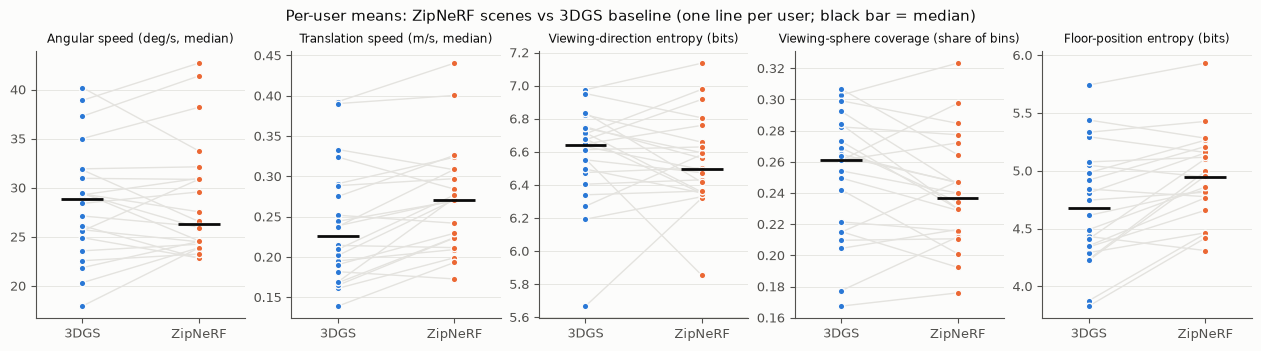

In [8]:
wide = {m: analysis.group_wide(measures, m) for m in analysis.MEASURES}
fig = plots.paired_panels(wide, "3DGS", "ZipNeRF", "Per-user means: ZipNeRF scenes vs 3DGS baseline", (plots.GROUP_COLORS["3DGS"], plots.GROUP_COLORS["ZipNeRF"]))
fig.savefig(FIG / "fig3_group_comparison.png"); plt.show()

**Sensitivity**: the same test without the traces flagged for position jumps.

In [9]:
flagged = {(r["user"], r["scene"]) for r in qc_summary["position_jump_traces"]}
clean = measures[[(u, s) not in flagged for u, s in zip(measures.user, measures.scene)]]
sens = analysis.compare_groups(clean)
sens.to_csv(RES / "sensitivity_no_jump_traces.csv", index=False)
sens[["measure", "n", "test", "diff", "effect_size", "p_holm", "significant"]]

,measure,n,test,diff,effect_size,p_holm,significant
0,ang_speed_deg_s,22,paired t,0.120,0.034,1.000,False
1,trans_speed_m_s,22,paired t,0.034,0.898,0.002,True
2,dir_entropy_bits,22,paired t,-0.030,-0.103,1.000,False
3,dir_coverage,22,paired t,-0.009,-0.331,0.405,False
4,pos_entropy_bits,22,paired t,0.266,0.866,0.002,True


**Robustness**: (a) is the group difference driven by one ZipNeRF scene? Re-run leaving each ZipNeRF scene out. (b) Could scene scale (which sets the rounding resolution in metres) explain per-scene speed? Spearman correlation of scene scale with the per-scene median, n = 12 scenes.

In [10]:
from scipy.stats import spearmanr
loo = []
for sc in sorted(load.ZIPNERF_SCENES):
    r = analysis.compare_groups(measures[measures.scene != sc])
    loo += [{"left_out": sc, **row} for row in r[["measure", "diff", "effect_size", "p_holm", "significant"]].to_dict("records")]
loo = pd.DataFrame(loo); loo.to_csv(RES / "leave_one_zipnerf_scene_out.csv", index=False)
display(loo[loo.measure.isin(["trans_speed_m_s", "pos_entropy_bits"])])
per_scene = measures.groupby("scene")[analysis.MEASURES].median().join(settings["scale"])
per_scene.to_csv(RES / "per_scene_medians.csv")
scale_rho = {m: dict(zip(["rho", "p"], map(float, spearmanr(per_scene.scale, per_scene[m])))) for m in ["trans_speed_m_s", "pos_entropy_bits"]}
summary["leave_one_out"] = loo.to_dict("records"); summary["scale_vs_scene_median"] = scale_rho
display(per_scene.sort_values("trans_speed_m_s")); scale_rho

,left_out,measure,diff,effect_size,p_holm,significant
1,alameda,trans_speed_m_s,0.030,0.776,7.696e-03,True
4,alameda,pos_entropy_bits,0.231,0.707,1.313e-02,True
6,berlin,trans_speed_m_s,0.042,1.163,1.034e-04,True
9,berlin,pos_entropy_bits,0.309,0.972,6.845e-04,True
11,london,trans_speed_m_s,0.034,0.832,3.266e-03,True
14,london,pos_entropy_bits,0.284,0.915,1.616e-03,True
16,nyc,trans_speed_m_s,0.020,0.550,7.025e-02,False
19,nyc,pos_entropy_bits,0.188,0.660,2.729e-02,True


,ang_speed_deg_s,trans_speed_m_s,dir_entropy_bits,dir_coverage,pos_entropy_bits,scale
scene,,,,,,
train,26.290,0.188,6.520,0.222,4.560,0.36
stump,28.765,0.195,6.609,0.247,4.659,1.00
playroom,28.708,0.211,6.805,0.284,4.639,2.70
berlin,27.868,0.222,6.647,0.253,4.679,0.80
bicycle,28.558,0.227,6.613,0.256,4.955,1.25
truck,27.019,0.233,6.675,0.241,4.879,0.76
room,28.370,0.234,6.736,0.253,4.772,2.00
treehill,27.005,0.246,6.662,0.264,4.896,1.00
alameda,28.362,0.247,6.475,0.218,4.997,0.64


{'trans_speed_m_s': {'rho': -0.1940110709403283, 'p': 0.5457153559319013},
 'pos_entropy_bits': {'rho': -0.17284622683774703, 'p': 0.5911312055661145}}

## 4. Secondary: do the 12 scenes differ at all? (Friedman, Kendall's W, Holm across measures)

Users with all 12 scenes only (complete-case).

In [11]:
scenes_res = analysis.compare_scenes(measures)
scenes_res.to_csv(RES / "friedman_scenes.csv", index=False); scenes_res

,measure,n,k,chi2,p,kendall_w,p_holm,significant
0,ang_speed_deg_s,17,12,8.131,7.015e-01,0.043,7.015e-01,False
1,trans_speed_m_s,17,12,36.973,1.164e-04,0.198,4.658e-04,True
2,dir_entropy_bits,17,12,12.828,3.047e-01,0.069,6.094e-01,False
3,dir_coverage,17,12,21.504,2.851e-02,0.115,8.554e-02,False
4,pos_entropy_bits,17,12,41.027,2.384e-05,0.219,1.192e-04,True


## 5. Early (0-20 s) vs late (40-60 s) exploration

Per user, each phase's measure averaged over scenes; same test-selection rule and Holm correction as above.

In [12]:
phases = analysis.compare_phases(windows)
phases.to_csv(RES / "early_vs_late.csv", index=False)
phases[["measure", "n", "shapiro_p", "test", "centre", "diff", "diff_ci_lo", "diff_ci_hi", "effect", "effect_size", "es_ci_lo", "es_ci_hi", "p", "p_holm", "significant"]]

,measure,n,shapiro_p,test,centre,diff,diff_ci_lo,diff_ci_hi,effect,effect_size,es_ci_lo,es_ci_hi,p,p_holm,significant
0,ang_speed_deg_s,22,0.739,paired t,mean_diff,-2.918,-4.744,-1.123,dz,-0.647,-1.154,-0.272,0.006,0.032,True
1,trans_speed_m_s,22,0.562,paired t,mean_diff,0.003,-0.021,0.025,dz,0.049,-0.362,0.559,0.820,1.000,False
2,dir_entropy_bits,22,0.919,paired t,mean_diff,-0.171,-0.294,-0.050,dz,-0.572,-1.079,-0.181,0.014,0.052,False
3,dir_coverage,22,0.793,paired t,mean_diff,-0.010,-0.016,-0.003,dz,-0.578,-1.081,-0.185,0.013,0.052,False
4,pos_entropy_bits,22,0.768,paired t,mean_diff,0.009,-0.174,0.186,dz,0.020,-0.401,0.483,0.926,1.000,False


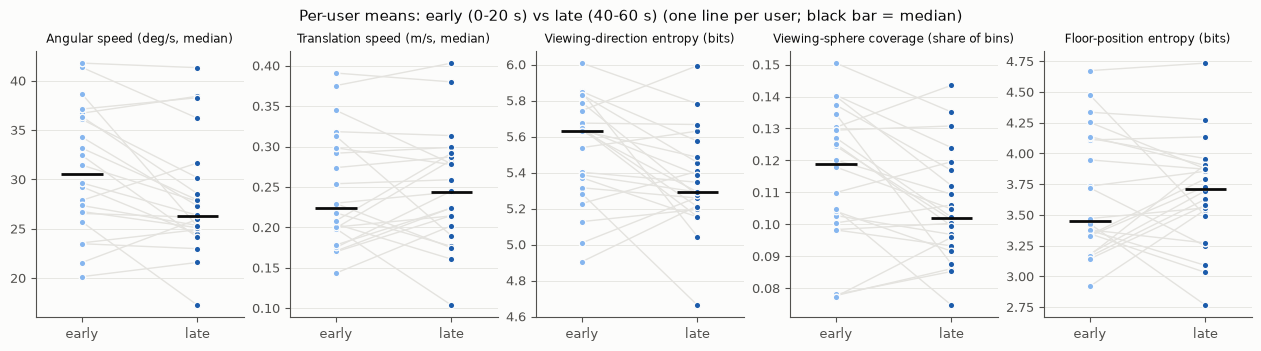

In [13]:
pw = {m: analysis.phase_wide(windows, m) for m in analysis.MEASURES}
fig = plots.paired_panels(pw, "early", "late", "Per-user means: early (0-20 s) vs late (40-60 s)", ("#86b6ef", "#1c5cab"))
fig.savefig(FIG / "fig4_early_vs_late.png"); plt.show()

## 6. Figures: dwell maps and time course

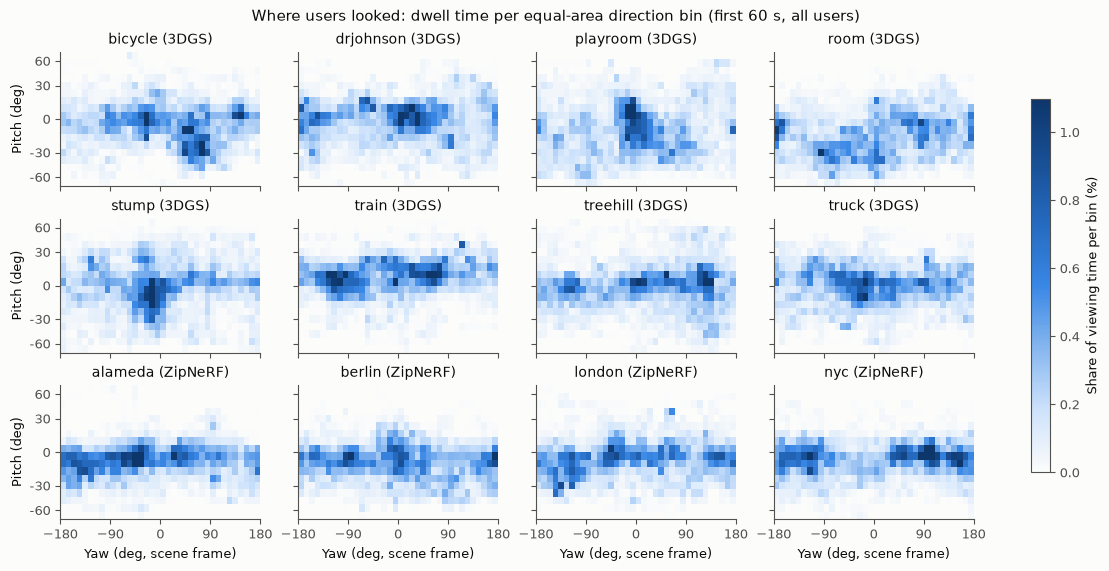

In [14]:
scenes = sorted(measures.scene.unique(), key=lambda s: (load.scene_group(s), s))
fig = plots.dwell_maps(dwell, scenes, {s: load.scene_group(s) for s in scenes}, pipeline.N_YAW, pipeline.N_PITCH)
fig.savefig(FIG / "fig1_dwell_maps.png"); plt.show()

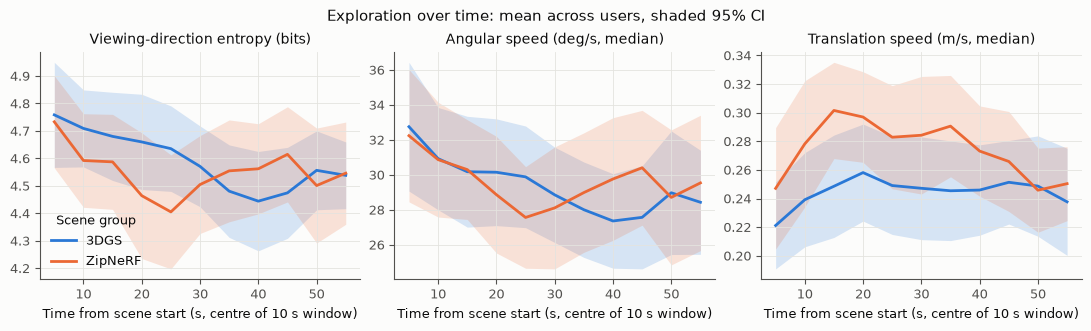

In [15]:
fig = plots.time_course(windows, ["dir_entropy_bits", "ang_speed_deg_s", "trans_speed_m_s"])
fig.savefig(FIG / "fig2_time_course.png"); plt.show()

## 7. Save summary

In [16]:
def records(df, cols):
    return df[cols].to_dict("records")
cols = ["measure", "n", "shapiro_p", "test", "centre", "diff", "diff_ci_lo", "diff_ci_hi", "effect", "effect_size", "es_ci_lo", "es_ci_hi", "p", "p_holm", "significant"]
summary["descriptives_median_by_group"] = by_group.to_dict()
summary["primary"] = records(primary, cols)
summary["sensitivity"] = records(sens, ["measure", "n", "test", "diff", "effect_size", "p_holm", "significant"])
summary["friedman"] = records(scenes_res, ["measure", "n", "k", "chi2", "p", "kendall_w", "p_holm", "significant"])
summary["early_late"] = records(phases, cols)
(RES / "summary.json").write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("wrote", RES / "summary.json")

wrote /home/athul_rohan/Documents/VS Code/Claude/vr-exploration-behaviour-analysis/results/summary.json
